# Tópicos en noticias en español con BERTopic

**Corpus:** MLSUM-es (artículos de *El País*, junio–octubre 2019), split `test`.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import torch
from huggingface_hub import hf_hub_download
from nltk.corpus import stopwords
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance

SEED = 14
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
DATA = Path("data"); DATA.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 200)

## 1. Segmentación

**1 documento = título + entradilla de un artículo.** El cuerpo mide ~784 palabras en promedio, no tiene saltos de párrafo y excede el límite de 128 tokens del modelo; la entradilla es el resumen que escribe el periodista.

Limpieza: se quita la sección `elpais inenglish` (en inglés), los segmentos con menos de 5 palabras y los duplicados.

In [2]:
src = DATA / "mlsum_es_test.parquet"
if not src.exists():
    p = hf_hub_download("mlsum", "es/test/0000.parquet", repo_type="dataset", revision="refs/convert/parquet")
    pd.read_parquet(p).to_parquet(src)
raw = pd.read_parquet(src)

df = raw[raw.topic != "elpais inenglish"].copy()
df["doc"] = (df.title.str.strip().str.rstrip(".") + ". " + df.summary.str.strip()).str.replace(r"\s+", " ", regex=True)
df["n_palabras"] = df.doc.str.split().str.len()
df = df[df.n_palabras >= 5].drop_duplicates("doc").reset_index(drop=True)
docs = df.doc.tolist()
print(f"Artículos originales: {len(raw)} | segmentos finales: {len(df)}")

Artículos originales: 13920 | segmentos finales: 13613


Token indices sequence length is longer than the specified maximum sequence length for this model (140 > 128). Running this sequence through the model will result in indexing errors


Segmentos: 13613
Longitud promedio: 31.7 palabras (46.7 tokens)
Truncados (> 128 tokens): 0.11%


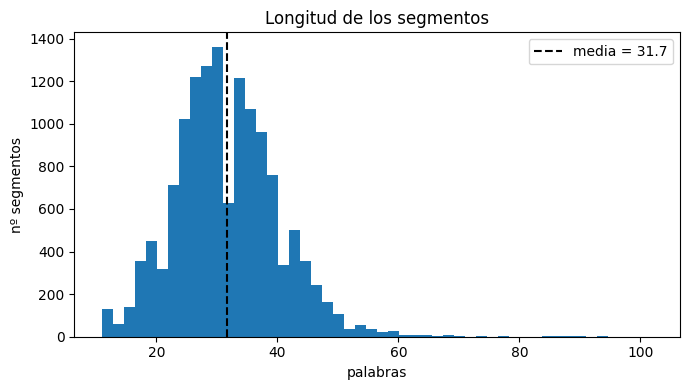

In [3]:
EMB_MODEL = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
encoder = SentenceTransformer(EMB_MODEL, device=device)
df["n_tokens"] = [len(t) for t in encoder.tokenizer(docs)["input_ids"]]

print(f"Segmentos: {len(df)}")
print(f"Longitud promedio: {df.n_palabras.mean():.1f} palabras ({df.n_tokens.mean():.1f} tokens)")
print(f"Truncados (> {encoder.max_seq_length} tokens): {100 * (df.n_tokens > encoder.max_seq_length).mean():.2f}%")

plt.figure(figsize=(7, 4))
plt.hist(df.n_palabras, bins=50)
plt.axvline(df.n_palabras.mean(), color="k", ls="--", label=f"media = {df.n_palabras.mean():.1f}")
plt.title("Longitud de los segmentos"); plt.xlabel("palabras"); plt.ylabel("nº segmentos"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "histograma_longitudes.png", dpi=150); plt.show()

## 2. Modelado

**Embeddings:** `paraphrase-multilingual-mpnet-base-v2`, modelo multilingüe (incluye español) de 768 dimensiones con límite de 128 tokens, suficiente para nuestros segmentos.

- **UMAP** `n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=14` (reproducible).
- **HDBSCAN** para agrupar sin fijar el número de tópicos.
- **CountVectorizer** con stopwords en español (NLTK + algunas palabras periodísticas) y `min_df=5`.

Configuraciones comparadas:
- **A:** `min_cluster_size=30`, selección `eom`, `ngram_range=(1,1)`, `nr_topics=None`.
- **B:** `min_cluster_size=80`, selección `leaf`, `ngram_range=(1,2)`, `nr_topics=None`, MMR.
- **C:** `min_cluster_size=50`, selección `leaf`, `ngram_range=(1,2)`, `nr_topics=None`, MMR.

`ngram_range` define si las palabras clave son solo palabras sueltas `(1,1)` o también pares de palabras `(1,2)`. `nr_topics` fusiona los tópicos más parecidos hasta llegar a un número dado; con `None` se conservan los tópicos que encuentra HDBSCAN.

In [4]:
embeddings = encoder.encode(docs, batch_size=64, show_progress_bar=True)

Batches:   0%|          | 0/213 [00:00<?, ?it/s]

In [5]:
nltk.download("stopwords", quiet=True)
STOPWORDS = stopwords.words("spanish") + [
    "si", "así", "dos", "tras", "ser", "hace", "según", "año", "años", "ahora", "puede", "va",
    "vez", "solo", "sólo", "cómo", "qué", "cuando", "dice", "hoy", "ya", "además", "sido",
]

def make_vectorizer(ngram_range):
    return CountVectorizer(stop_words=STOPWORDS, ngram_range=ngram_range, min_df=5)

def make_mmr():
    return MaximalMarginalRelevance(diversity=0.3)

def make_model(min_cluster_size, selection, ngram_range, nr_topics, mmr):
    return BERTopic(
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=min_cluster_size, min_samples=10,
                              cluster_selection_method=selection, prediction_data=True),
        vectorizer_model=make_vectorizer(ngram_range),
        representation_model=make_mmr() if mmr else None,
        nr_topics=nr_topics,
        language="multilingual",
    )

configs = {
    "A": dict(min_cluster_size=30, selection="eom", ngram_range=(1, 1), nr_topics=None, mmr=False),
    "B": dict(min_cluster_size=80, selection="leaf", ngram_range=(1, 2), nr_topics=None, mmr=True),
    "C": dict(min_cluster_size=50, selection="leaf", ngram_range=(1, 2), nr_topics=None, mmr=True),
}

In [6]:
models, rows = {}, []
for name, cfg in configs.items():
    m = make_model(**cfg)
    t = np.asarray(m.fit_transform(docs, embeddings)[0])
    models[name] = (m, t)
    rows.append({"config": name, "n_topicos": t.max() + 1, "% outliers": round(100 * (t == -1).mean(), 1),
                 "tópico más grande": np.bincount(t[t != -1]).max()})
pd.DataFrame(rows).set_index("config")

,n_topicos,% outliers,tópico más grande
config,,,
A,77,36.6,852
B,42,40.9,586
C,62,45.6,375


In [7]:
for name, (m, _) in models.items():
    print(f"\n=== Config {name} ===")
    print(m.get_topic_info().head(11)[["Topic", "Count", "Name"]].to_string(index=False))


=== Config A ===
 Topic  Count                                   Name
    -1   4981         -1_madrid_vida_millones_españa
     0    852              0_psoe_sánchez_pp_podemos
     1    729          1_fútbol_mundial_equipo_final
     2    367 2_elecciones_pactos_políticos_política
     3    302    3_música_festival_concierto_musical
     4    270        4_detenido_hombre_policía_mujer
     5    229       5_ofertas_mejores_amazon_precios
     6    228    6_cataluña_barcelona_procés_catalán
     7    200         7_príncipe_princesa_reina_boda
     8    191      8_película_novela_cine_literatura
     9    185            9_ciudad_hoteles_ruta_hotel

=== Config B ===
 Topic  Count                                        Name
    -1   5574                    -1_roto_país_gobierno_pp
     0    586           0_cantante_música_actriz_festival
     1    427 1_climático_cambio climático_cambio_planeta
     2    412            2_equipo_fútbol_atlético_mundial
     3    375             3_detenido_h

**Comparación:** A produce ~77 tópicos muy específicos y, a la vez, un tópico enorme (852 documentos) que mezcla toda la política nacional (PSOE, PP, Podemos). B produce ~40 tópicos más fáciles de interpretar, y los bigramas aportan términos como *cambio climático* o *madrid central*. C, que solo cambia `min_cluster_size` a 50, queda en un punto intermedio (62 tópicos), pero aumenta los outliers (46 %) y vuelve a dividir algunos temas en tópicos más pequeños. **Se elige B.**

## 3. Outliers

B deja ~41 % de documentos como −1, normal en noticias (columnas de opinión, piezas únicas). Se reasignan con `reduce_outliers(strategy="embeddings", threshold=0.5)`: cada outlier va al tópico más similar solo si la similitud coseno es ≥ 0.5, así que los ambiguos siguen en −1.

In [8]:
topic_model, topics = models["B"]
new_topics = topic_model.reduce_outliers(docs, topics, strategy="embeddings", embeddings=embeddings, threshold=0.5)
topic_model.update_topics(docs, topics=new_topics,
                          vectorizer_model=make_vectorizer(configs["B"]["ngram_range"]),
                          representation_model=make_mmr())
print(f"Outliers antes: {100 * (topics == -1).mean():.1f}%  |  después: {100 * (np.asarray(new_topics) == -1).mean():.1f}%")

2026-10-30 19:13:50,688 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers antes: 40.9%  |  después: 11.6%


## 4. Tabla de tópicos con nombre propio

In [9]:
LABELS = {
    0: "Música y celebridades",
    1: "Cambio climático y sostenibilidad",
    2: "Fútbol",
    3: "Sucesos y detenciones",
    4: "Repetición electoral (10-N)",
    5: "Tribunales y justicia",
    6: "Economía española y global",
    7: "Guía de TV y resumen diario (formato)",
    8: "Ofertas y compras (Escaparate)",
    9: "Cataluña y el procés",
    10: "Geopolítica: Trump, Israel, Irán",
    11: "Violencia de género y feminismo",
    12: "Ayuntamiento de Madrid / Madrid Central",
    13: "Realeza",
    14: "Cine de Hollywood y novela",
    15: "Salud y brotes sanitarios",
    16: "Viajes y hoteles",
    17: "Educación",
    18: "México y Venezuela",
    19: "Migración y Open Arms",
    20: "Brexit",
    21: "Motor, tenis y ciclismo",
    22: "Unión Europea",
    23: "Exhumación de Franco",
    24: "Literatura y libros",
    25: "Arte y museos",
    26: "Gastronomía y restaurantes",
    27: "Medios de comunicación y ensayo de opinión",
    28: "Colombia y Bolivia",
    29: "Accidentes",
    30: "Festivales de cine y viñetas de El Roto (mixto)",
    31: "Crianza e infancia",
    32: "Incendios forestales",
    33: "Alimentación y dieta",
    34: "Vivienda y alquiler",
    35: "PSOE-Podemos: gobierno de coalición",
    36: "Investidura de Sánchez",
    37: "Resultados empresariales",
    38: "Privacidad y redes sociales",
    39: "PP, Ayuso y Ciudadanos",
    40: "Inteligencia artificial y economía digital",
    41: "Huelgas en aeropuertos",
}
topic_model.set_topic_labels(LABELS)

info = topic_model.get_topic_info()
info["Palabras clave"] = info.Representation.apply(lambda ws: ", ".join(ws[:8]))
tabla = info[["Topic", "CustomName", "Count", "Palabras clave"]].rename(columns={"CustomName": "Nombre", "Count": "Docs"})
tabla.loc[tabla.Topic == -1, "Nombre"] = "Outliers"
tabla.to_csv("tabla_topicos.csv", index=False)
with pd.option_context("display.max_rows", 100):
    display(tabla)

,Topic,Nombre,Docs,Palabras clave
0,-1,Outliers,1582,"china, hong kong, kong, hong, millones, 000, vida, euros"
1,0,Música y celebridades,741,"cantante, música, festival, actriz, musical, disco, vida, concierto"
2,1,Cambio climático y sostenibilidad,537,"climático, cambio climático, cambio, planeta, climática, global, sostenible, clima"
3,2,Fútbol,474,"fútbol, equipo, mundial, real madrid, atlético, madrid, partido, real"
4,3,Sucesos y detenciones,442,"detenido, hombre, mujer, policía, víctima, prisión, joven, detenidos"
5,4,Repetición electoral (10-N),586,"elecciones, política, políticos, electoral, partidos, pactos, democracia, debate"
6,5,Tribunales y justicia,494,"juez, tribunal, supremo, torra, caso, fiscalía, sentencia, juicio"
7,6,Economía española y global,454,"economía, banco, deuda, españa, millones, tipos, crecimiento, empleo"
8,7,Guía de TV y resumen diario (formato),313,"ver, 2019, actualidad, historias, jornada, noticias, clave, selección"
9,8,Ofertas y compras (Escaparate),245,"mejores, ofertas, amazon, precios, productos, 15, selección, modelos"


## 5. Segmentos representativos (2 por tópico)

In [10]:
rep = topic_model.get_representative_docs()
rep_df = pd.DataFrame([{"Topic": k, "Nombre": LABELS[k], "Segmento": d}
                       for k in sorted(rep) if k != -1 for d in rep[k][:2]])
rep_df.to_csv("segmentos_representativos.csv", index=False)
with pd.option_context("display.max_rows", 100):
    display(rep_df)

,Topic,Nombre,Segmento
0,0,Música y celebridades,"Un festival para una comarca. El Festival Bal y Gay lleva a A Mariña de Lugo lo mejor de la música clásica con conciertos, divulgación y didáctica de alto nivel"
1,0,Música y celebridades,Rulo: “En la música solo hay un baremo: o te pellizca o no te pellizca”. El cantante y compositor habla sobre su nuevo disco que saldrá en noviembre y cómo ve a las nuevas generaciones de artistas
2,1,Cambio climático y sostenibilidad,Cambio climático: No es suficiente. Los Gobiernos deben asumir mayores compromisos ante el cambio climático
3,1,Cambio climático y sostenibilidad,cambio climático: El reto político del cambio climático. Exijamos a nuestros líderes que lean a nuestros científicos y que actúen en consecuencia. No tenemos un planeta B
4,2,Fútbol,"La nueva fábrica de jugadoras. Cómo el fútbol español copa el Mundial de Francia. Una de cada 10 futbolistas del torneo compitieron la última temporada en España. El FC Barcelona, con 15, es el cl..."
5,2,Fútbol,Mundial de Fútbol Femenino 2019: resultados de los partidos. Estados Unidos gana la octava edición de la Copa Mundial Femenina de fútbol en Francia. Así ha sido el resto de partidos
6,3,Sucesos y detenciones,"Prisión provisional para un hombre por golpear y agredir sexualmente a su madre. El detenido desfiguró a la víctima, de 76 años, de un golpe en la cara en su domicilio en Parla (Madrid)"
7,3,Sucesos y detenciones,Detenido un hombre en Vilafranca del Penedès por un homicidio en un local de ocio de Madrid. El acusado fue detenido en un control policial montado específicamente para arrestarlo
8,4,Repetición electoral (10-N),"10-N: ¿Fin de la política?. No son los políticos en tanto que personas, es la política en tanto que poder la que está cada vez más limitada y desorientada"
9,4,Repetición electoral (10-N),Elecciones generales: En el tablero no hay sitio para el acuerdo. La repetición de las elecciones generales puede explicarse por una combinación de factores sistémicos con la debilidad organizativ...


## 6. Visualizaciones

In [11]:
fig = topic_model.visualize_barchart(top_n_topics=12, n_words=6, custom_labels=True, width=280, height=250)
fig.write_image(FIG / "barchart.png", scale=2)
fig

In [12]:
fig = topic_model.visualize_hierarchy(custom_labels=True, width=1000, height=1000)
fig.write_image(FIG / "jerarquia.png", scale=2)
fig